In [ ]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys, re
sys.setrecursionlimit(1000000)
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
from functools import reduce
from tqdm.auto import tqdm
import swifter

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from rdkit.DataStructs import TanimotoSimilarity
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.Chem import Descriptors
from rdkit import DataStructs

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {
    "toImageButtonOptions": {"format": "png", "scale": 5}}

sys.path.append(os.path.abspath(R"C:\\Users\\Idener\\Sync\\CODE"))
from AIDDTools import fingerprint_tools as fpt
clear_output()

## OLD

In [ ]:
df_cpd = pd.read_csv('../data/Database_KEGG_cpd.csv')
df_cpd = df_cpd.iloc[20:].dropna(subset=['FORMULA', 'INCHI', 'REACTION'])
df_cpd = df_cpd[df_cpd['MOL_WEIGHT'] > 50]

allowed_elements = R'(C|H|N|O|F|Cl|Br|P|S)'
pattern = rf'^({allowed_elements}[0-9]*)+$'
df_cpd = df_cpd[
    df_cpd['FORMULA'].str.fullmatch(pattern, case=False, na=False) &
    df_cpd['FORMULA'].str.contains('C', case=False, na=False) &
    df_cpd['FORMULA'].str.contains('H', case=False, na=False)]

df_cpd

In [ ]:
db_folder = R"C:\Users\Idener\Sync\CODE\fantastic-biofragmenter\data"
df_pairs = pd.read_parquet(Rf"{db_folder}\Database_KEGG_rn.gzip", engine='fastparquet')
df_pairs = df_pairs.explode('RPAIR')
df_pairs['RPAIR'] = df_pairs['RPAIR'].apply(lambda x: x.split('_'))
df_pairs['RPAIR'] = df_pairs['RPAIR'].apply(lambda x: [df_cpd.loc[df_cpd['ENTRY'] == r, 'ISOSMILES'].values[0]
                                                 if not df_cpd.loc[df_cpd['ENTRY'] == r, 'ISOSMILES'].empty
                                                 else None for r in x])
df_pairs = df_pairs[df_pairs['RPAIR'].apply(lambda x: all(x))]

df_pairs[['RPAIR_1', 'RPAIR_2']] = pd.DataFrame(df_pairs['RPAIR'].tolist(), index=df_pairs.index)
PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Reactant', molCol='ROMOL_1')
PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Product', molCol='ROMOL_2')
df_pairs = df_pairs.dropna(subset=['ROMOL_1', 'ROMOL_2'])

df_pairs['ATOMS_R'] = df_pairs['ROMOL_1'].apply(lambda x: x.GetNumHeavyAtoms() if x else None)
df_pairs['Product_ATOMS'] = df_pairs['ROMOL_2'].apply(lambda x: x.GetNumHeavyAtoms() if x else None)
df_pairs['ATOM_DIFF'] = abs(df_pairs['ATOMS_R'] - df_pairs['Product_ATOMS'])
df_pairs = df_pairs[df_pairs['ATOM_DIFF'] <= 5]

df_pairs = df_pairs[['REACTION', 'EQUATION', 'BRITE', 'Reactant', 'Product', 'ATOM_DIFF', 'ROMOL_1', 'ROMOL_2']]

In [ ]:
methods = ['maccs', 'rdkit', 'morgan2', 'morgan3', 'avalon', 'torsion', 'mhfp', 'mhfp6']

for method in methods:
    df_pairs['FP_1'] = df_pairs['ROMOL_1'].apply(lambda mol: calculate_fp(mol, method=method))
    df_pairs['FP_2'] = df_pairs['ROMOL_2'].apply(lambda mol: calculate_fp(mol, method=method))
    df_pairs[f'similarity_{method}'] = df_pairs.apply(lambda row: get_similarity(row['FP_1'], row['FP_2'], method=method), axis=1)

df_pairs.drop(columns=['FP_1', 'FP_2', 'ROMOL_1', 'ROMOL_2']).to_csv(R"C:\Users\Idener\Desktop\KEGG_RPAIRS.csv", index=False)
df_pairs

In [ ]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

bin_edges = np.arange(0, 1.1, 0.1)
bin_labels = [f"{round(bin_edges[i], 1)}–{round(bin_edges[i+1], 1)}" for i in range(len(bin_edges)-1)][::-1]

# Determine number of rows and columns for subplots (2x3 grid here)
rows = 2
cols = 4

# Calculate counts for all methods first to find the global max
all_counts = []
for method in methods:
    df_1 = df_pairs.copy().dropna(subset=['BRITE'])
    df_1 = df_1[df_1['BRITE'].str.contains('5. Isomerase reactions')]
    similarities = df_1[f'similarity_{method}'].dropna()
    counts, _ = np.histogram(similarities, bins=bin_edges)
    counts = counts[::-1]  # reverse to match reversed x-axis
    all_counts.append(counts)
max_count = max([max(counts) for counts in all_counts])

fig = make_subplots(rows=rows, cols=cols, subplot_titles=[m.upper() for m in methods])

for i, method in enumerate(methods):
    row = i // cols + 1
    col = i % cols + 1

    counts = all_counts[i]

    fig.add_trace(
        go.Bar(x=bin_labels, y=counts, name=method.upper(), showlegend=False),
        row=row, col=col
    )

    fig.update_xaxes(title_text="Similarity", categoryorder='array', categoryarray=bin_labels, row=row, col=col)
    fig.update_yaxes(title_text="Count", range=[0, max_count], row=row, col=col)  # same y-axis max

fig.update_layout(
    title="Similarity Distributions per Fingerprint Method",
    height=600,
    width=1000,
    template="plotly_white"
)

fig.show()

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Define thresholds
thresholds = np.arange(0.0, 1.01, 0.05)

# Collect correlation data
results = {method: {'thresholds': [], 'pearson': [], 'spearman': []} for method in methods}

for method in methods:
    for threshold in thresholds:
        subdf = df_pairs[df_pairs[f'similarity_{method}'] >= threshold].dropna(subset=['ATOM_DIFF'])
        if subdf.shape[0] >= 5:
            corr_pearson = subdf[[f'similarity_{method}', 'ATOM_DIFF']].corr(method='pearson').iloc[0, 1]
            corr_spearman = subdf[[f'similarity_{method}', 'ATOM_DIFF']].corr(method='spearman').iloc[0, 1]
        else:
            corr_pearson = np.nan
            corr_spearman = np.nan

        results[method]['thresholds'].append(threshold)
        results[method]['pearson'].append(abs(corr_pearson))
        results[method]['spearman'].append(abs(corr_spearman))

# --- Pearson Plot ---
fig_pearson = go.Figure()
for method in methods:
    fig_pearson.add_trace(go.Scatter(
        x=results[method]['thresholds'],
        y=results[method]['pearson'],
        mode='lines+markers',
        name=method.upper()
    ))

fig_pearson.update_layout(
    title='|Pearson Correlation| vs Similarity Threshold',
    xaxis_title='Similarity Threshold (Descending)',
    yaxis_title='|Pearson r|',
    xaxis=dict(autorange='reversed'),
    template='plotly_white',
    width=900,
    height=500
)

# --- Spearman Plot ---
fig_spearman = go.Figure()
for method in methods:
    fig_spearman.add_trace(go.Scatter(
        x=results[method]['thresholds'],
        y=results[method]['spearman'],
        mode='lines+markers',
        name=method.upper()
    ))

fig_spearman.update_layout(
    title='|Spearman Correlation| vs Similarity Threshold',
    xaxis_title='Similarity Threshold (Descending)',
    yaxis_title='|Spearman ρ|',
    xaxis=dict(autorange='reversed'),
    template='plotly_white',
    width=900,
    height=500
)

# Show both plots
fig_pearson.show()
fig_spearman.show()


In [ ]:
from skfp.fingerprints import MACCSFingerprint, PubChemFingerprint

smiles_list = ["O=S(=O)(O)CCS(=O)(=O)O", "O=C(O)c1ccccc1O"]
mols = [Chem.MolFromSmiles(smiles) for smiles in smiles_list]


# fp_maccs = MACCSFingerprint(n_jobs=-1)
# fp_maccs_count = MACCSFingerprint(count=True, n_jobs=-1)

fp_pubchem = PubChemFingerprint(n_jobs=-1)
fp_pubchem_count = PubChemFingerprint(count=True, n_jobs=-1)

# X_maccs = fp_maccs.transform(mols)
# X_maccs_count = fp_maccs_count.transform(mols)

X_pubchem = fp_pubchem.transform(mols)
# X_pubchem_count = fp_pubchem_count.transform(mols)
X_pubchem

In [ ]:
sys.path.append(os.path.abspath("C:\\Users\\Idener\\Documents\\MEGA\\drug_design_modules\\NC-MFP"))

from itertools import chain
from NC_MFP_Algorithm.Preprocessing_step import Preprocessing
from NC_MFP_Algorithm.Scaffold_matching_step import Scaffold_Matching
from NC_MFP_Algorithm.Fragment_list_generation_step import Fragment_List_Generation
from NC_MFP_Algorithm.SFCP_assigning_step import SFCP_Assigning
from NC_MFP_Algorithm.Fragment_identifying_step import Fragment_identifying
from NC_MFP_Algorithm.Fingerprint_representation_step import Fingerprint_representation

# Define classes
Step_1 = Preprocessing()
Step_2 = Scaffold_Matching()
Step_3 = Fragment_List_Generation()
Step_4 = SFCP_Assigning()
Step_5 = Fragment_identifying()
Step_6 = Fingerprint_representation()

All_Scaffold_FilePath = ('C:\\Users\\Idener\\Documents\\MEGA\\drug_design_modules\\NC-MFP\\Data\\All_Optimized_Scaffold_List.txt')

# qMols_Smarts = Step_1.get_Query_Mols_Smarts(Query_FilePath)
qMols_Smarts = df_pairs['ROMOL_1'].apply(Chem.MolToSmarts).dropna().tolist()[:500]

Final_all_Fragment_List = []
for qMol_Smart in qMols_Smarts:
    fragments = Step_3.generate_all_Fragment_List(All_Scaffold_FilePath, qMol_Smart) or [qMol_Smart]
    Final_all_Fragment_List.append(fragments)
Final_all_Fragment_List = list(set(chain.from_iterable(Final_all_Fragment_List)))
Final_all_Fragment_Dic = Step_3.generate_all_Fragment_Dictionary(Final_all_Fragment_List)

Final_all_NC_MFP_Info = []
for smarts in tqdm(qMols_Smarts):
    # Step 2: Scaffold matching
    scaffold_matches = Step_2.match_All_Scaffold_Smarts(All_Scaffold_FilePath, smarts)
    scaffold_matches = list(set(scaffold_matches))  # Deduplicate

    # Step 4: Scaffold-Fragment Connection Pairs (SFCP)
    sfcp_list = Step_4.assign_all_sfcp_smarts(All_Scaffold_FilePath, smarts)

    # Step 5: Fragment identification
    try:
        fragment_list = Step_5.identify_Fragment_Smarts(All_Scaffold_FilePath, smarts, Final_all_Fragment_Dic)
    except: pass

    # Merge NC-MFP info
    merged_info = scaffold_matches + sfcp_list + fragment_list
    Final_all_NC_MFP_Info.append(merged_info)


# [6] Fingerprint representation step #
# Get all NC-MFP label
Final_all_NC_MFP_Label = Step_6.get_all_NC_MFP_Label(Final_all_NC_MFP_Info)

# Get all NC-MFP Bit String
Final_Bitstring = Step_6.get_qMol_NC_MFP_Value_Idx(Final_all_NC_MFP_Info, Final_all_NC_MFP_Label)
print(Final_Bitstring)

# NEW APPROACH

In [2]:
df_cpd = pd.read_csv('../data/Database_KEGG_cpd.csv', sep='\t')
df_cpd = df_cpd.iloc[20:].dropna(subset=['FORMULA', 'INCHI', 'REACTION'])
df_cpd = df_cpd[df_cpd['MOL_WEIGHT'] > 50]

allowed_elements = R'(C|H|N|O|F|Cl|Br|P|S)'
pattern = rf'^({allowed_elements}[0-9]*)+$'
df_cpd = df_cpd[
    df_cpd['FORMULA'].str.fullmatch(pattern, case=False, na=False) &
    df_cpd['FORMULA'].str.contains('C', case=False, na=False) &
    df_cpd['FORMULA'].str.contains('H', case=False, na=False)]

df_cpd

,ENTRY,NAME,FORMULA,MOL_WEIGHT,REACTION,ENZYME,PATHWAY,MODULE,NETWORK,BRITE,DBLINKS,REMARK,COMMENT,ISOSMILES,INCHI,INCHIKEY
20,C00021,"['S-Adenosyl-L-homocysteine', 'S-Adenosylhomoc...",C14H20N6O5S,384.4108,"['R00192', 'R00193', 'R00194', 'R00367', 'R003...","['1.16.1.8', '2.1.1.1', '2.1.1.2', '2.1.1.4', ...",{'map00270': 'Cysteine and methionine metaboli...,"{'M00035': 'Methionine degradation', 'M00609':...",NaN,NaN,"{'CAS': '979-92-0', 'PubChem': '3323', 'ChEBI'...",NaN,NaN,Nc1ncnc2c1ncn2C1OC(CSCCC(N)C(=O)O)C(O)C1O,ZJUKTBDSGOFHSH-UHFFFAOYSA-N,InChI=1S/C14H20N6O5S/c15-6(14(23)24)1-2-26-3-7...
21,C00022,"['Pyruvate', 'Pyruvic acid', '2-Oxopropanoate'...",C3H4O3,88.0621,"['R00006', 'R00008', 'R00014', 'R00195', 'R001...","['1.1.1.27', '1.1.1.28', '1.1.1.38', '1.1.1.39...","{'map00010': 'Glycolysis / Gluconeogenesis', '...",{'M00001': 'Glycolysis (Embden-Meyerhof pathwa...,"{'ELEMENT': {}, 'nt06031': 'Citrate cycle and ...",Compounds with biological roles [BR:br08001]\n...,"{'CAS': '127-17-3', 'PubChem': '3324', 'ChEBI'...",NaN,NaN,CC(=O)C(=O)O,LCTONWCANYUPML-UHFFFAOYSA-N,"InChI=1S/C3H4O3/c1-2(4)3(5)6/h1H3,(H,5,6)"
23,C00024,"['Acetyl-CoA', 'Acetyl coenzyme A']",C23H38N7O17P3S,809.5708,"['R00209', 'R00210', 'R00211', 'R00212', 'R002...","['1.1.1.-', '1.2.1.10', '1.2.1.18', '1.2.1.27'...","{'map00010': 'Glycolysis / Gluconeogenesis', '...","{'M00009': 'Citrate cycle (TCA cycle, Krebs cy...","{'ELEMENT': {}, 'nt06024': 'Valine, leucine an...",Lipids [BR:br08002]\n FA Fatty ac...,"{'CAS': '72-89-9', 'PubChem': '3326', 'ChEBI':...",NaN,NaN,CC(=O)SCCNC(=O)CCNC(=O)[C@H](O)C(C)(C)COP(=O)(...,ZSLZBFCDCINBPY-ZSJPKINUSA-N,InChI=1S/C23H38N7O17P3S/c1-12(31)51-7-6-25-14(...
24,C00025,"['L-Glutamate', 'L-Glutamic acid', 'L-Glutamin...",C5H9NO4,147.1293,"['R00021', 'R00093', 'R00114', 'R00239', 'R002...","['1.2.1.88', '1.4.1.2', '1.4.1.3', '1.4.1.4', ...","{'map00220': 'Arginine biosynthesis', 'map0025...","{'M00015': 'Proline biosynthesis, glutamate =>...","{'ELEMENT': {}, 'nt06010': 'Urea cycle', 'nt06...",Compounds with biological roles [BR:br08001]\n...,"{'CAS': '56-86-0', 'PubChem': '3327', 'ChEBI':...",['Same as: D00007'],NaN,N[C@@H](CCC(=O)O)C(=O)O,WHUUTDBJXJRKMK-VKHMYHEASA-N,"InChI=1S/C5H9NO4/c6-3(5(9)10)1-2-4(7)8/h3H,1-2..."
25,C00026,"['2-Oxoglutarate', 'Oxoglutaric acid', '2-Keto...",C5H6O5,146.0981,"['R00021', 'R00093', 'R00114', 'R00243', 'R002...","['1.1.1.41', '1.1.1.42', '1.1.1.95', '1.1.1.28...","{'map00020': 'Citrate cycle (TCA cycle)', 'map...","{'M00009': 'Citrate cycle (TCA cycle, Krebs cy...","{'ELEMENT': {}, 'nt06031': 'Citrate cycle and ...",Compounds with biological roles [BR:br08001]\n...,"{'CAS': '328-50-7', 'PubChem': '3328', 'ChEBI'...",NaN,NaN,O=C(O)CCC(=O)C(=O)O,KPGXRSRHYNQIFN-UHFFFAOYSA-N,"InChI=1S/C5H6O5/c6-3(5(9)10)1-2-4(7)8/h1-2H2,(..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18793,C22350,"['Levoglucosan', '1,6-Anhydro-beta-D-glucopyra...",C6H10O5,162.1406,"['R12713', 'R12746']","['1.1.1.425', '2.7.1.232']",NaN,NaN,NaN,NaN,"{'CAS': '498-07-7', 'ChEBI': '30997', 'PDB-CCD...",NaN,NaN,O[C@@H]1[C@@H](O)[C@@H]2OC[C@@H](O2)[C@H]1O,TWNIBLMWSKIRAT-VFUOTHLCSA-N,InChI=1S/C6H10O5/c7-3-2-1-10-6(11-2)5(9)4(3)8/...
18794,C22351,['3-Dehydrolevoglucosan'],C6H8O5,160.1247,['R12713'],['1.1.1.425'],NaN,NaN,NaN,NaN,{'ChEBI': '144894'},NaN,NaN,O=C1[C@@H](O)[C@@H]2OC[C@@H](O2)[C@H]1O,METXFULYFGSWDE-MNEPWGMJSA-N,InChI=1S/C6H8O5/c7-3-2-1-10-6(11-2)5(9)4(3)8/h...
18945,C22503,"['8-[(1R,2R)-3-Oxo-2-{(Z)-pent-2-enyl}cyclopen...",C18H30O3,294.4290,['R12992'],['1.3.1.42'],NaN,NaN,NaN,Lipids [BR:br08002]\n FA Fatty ac...,{'ChEBI': '15720 49265'},NaN,NaN,CC/C=C\C[C@H]1C(=O)CC[C@H]1CCCCCCCC(=O)O,BZXZFDKIRZBJEP-GTOOTHNYSA-N,InChI=1S/C18H30O3/c1-2-3-7-11-16-15(13-14-17(1...
19068,C22626,['N-Hydroxyguanidine'],CH5N3O,75.0699,"['R13112', 'R13115']",['4.4.1.43'],NaN,NaN,NaN,NaN,"{'ChEBI': '43089', 'PDB-CCD': 'HGU'}",NaN,NaN,N=C(N)NO,WFBHRSAKANVBKH-UHFFFAOYSA-N,"InChI=1S/CH5N3O/c2-1(3)4-5/h5H,(H4,2,3,4)"


,Reactant,Product,ROMOL_R,ROMOL_P
0,CC(=O)C(=O)O,CC(=O)C(C)(O)C(=O)O,,
1,CC(=O)C(=O)O,CC(O)(CC(=O)C(=O)O)C(=O)O,,
2,OC[CH]1OC(O)[CH](O)[CH](O)[CH]1O,OC[CH]1O[CH](O[CH]2O[CH](CO)[CH](O)[CH](O)[CH]...,,
3,Nc1nc2c(ncn2[CH]2O[CH](COP(=O)(O)OP(=O)(O)OP(=...,Nc1nc2c(ncn2[CH]2O[CH](COP(=O)(O)OP(=O)(O)OP(=...,,
4,O=CC(=O)O,O=CC(O)C(=O)O,,
...,...,...,...,...
9119,CC(C)C(=O)SCCN=C([O-])CCN=C([O-])[CH](O)C(C)(C...,C=C(C)C(=O)SCCN=C([O-])CCN=C([O-])[CH](O)C(C)(...,,
9120,C=C(C)C(=O)SCCN=C([O-])CCN=C([O-])[CH](O)C(C)(...,C[CH](CO)C(=O)SCCN=C([O-])CCN=C([O-])[CH](O)C(...,,
9121,C[CH](CO)C(=O)SCCN=C([O-])CCN=C([O-])[CH](O)C(...,C[CH](CO)C(=O)[O-],,
9122,C[CH](CO)C(=O)[O-],C[CH](C=O)C(=O)[O-],,

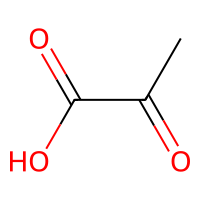
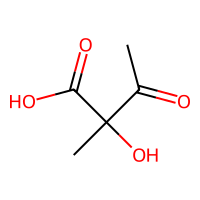
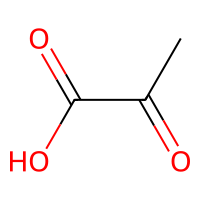
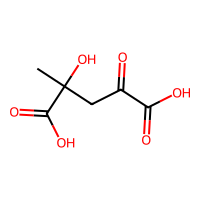
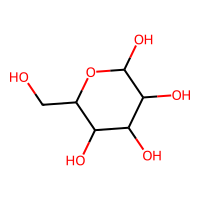
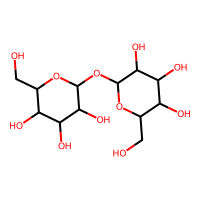
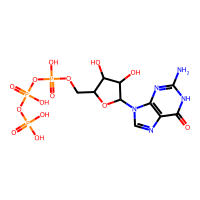
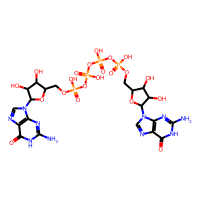
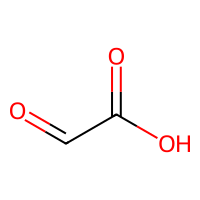
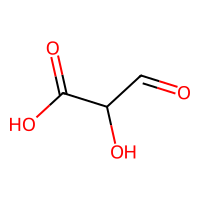
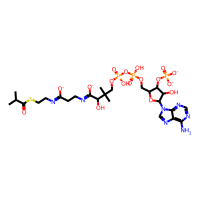
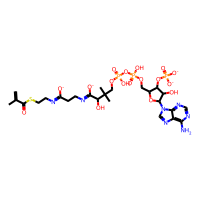
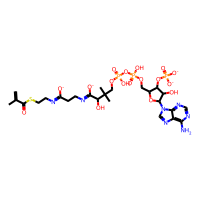
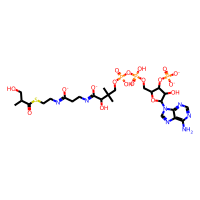
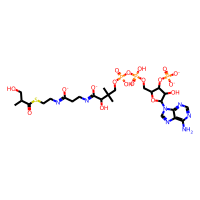
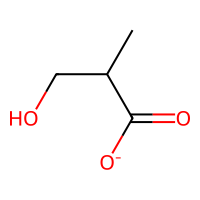
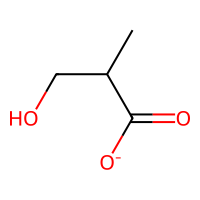
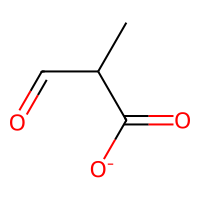
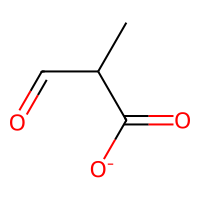
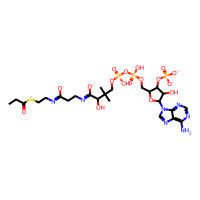

In [ ]:
db_folder = R"C:\Users\Idener\OneDrive - IDENER Research & Development AIE\SECRETed\fantastic-biofragmenter\data"
df1 = pd.read_parquet(Rf"{db_folder}\Database_KEGG_rn.gzip", engine='fastparquet')
df1 = df1.explode('RPAIR')
df1['RPAIR'] = df1['RPAIR'].apply(lambda x: x.split('_'))
df1['RPAIR'] = df1['RPAIR'].apply(lambda x: [df_cpd.loc[df_cpd['ENTRY'] == r, 'ISOSMILES'].values[0]
    if not df_cpd.loc[df_cpd['ENTRY'] == r, 'ISOSMILES'].empty else None for r in x])
df1 = df1[df1['RPAIR'].apply(lambda x: all(x))]


df2 = pd.read_csv("../data/biosynthetic_chains_smiles.tsv", sep='\t', header=None)
pairs = []
for _, row in df2.iterrows():
    smiles_chain = [s for s in row if pd.notna(s) and str(s).strip() != ""]
    for i in range(len(smiles_chain) - 1):
        pairs.append((smiles_chain[i], smiles_chain[i+1]))
df2 = pd.DataFrame(pairs, columns=["Reactant", "Product"])

In [93]:
# df3 = pd.read_csv("../data/rhea-reaction-smiles.tsv", sep='\t')
# df3 = df3.astype(str)
# df3 = df3[~df3.apply(lambda row: row.str.contains('\*', na=False)).any(axis=1)]
# df3['Reactants'] = df3['Reactants'].str.split('.')
# df3['Products'] = df3['Products'].str.split('.')

# import itertools

# # build Cartesian products row by row
# df3['Pairs'] = df3.apply(lambda row: list(itertools.product(
#     row['Reactants'], row['Products'])), axis=1)
# # explode into separate rows
# df3 = df3.explode('Pairs', ignore_index=True)
# # split pairs into two new columns
# df3['Reactant'] = df3['Pairs'].str[0]
# df3['Product']  = df3['Pairs'].str[1]
# # drop temporary column
# df3 = df3.drop(columns=['Pairs'])

# PandasTools.AddMoleculeColumnToFrame(df3, smilesCol='Reactant', molCol='ROMOL_R')
# PandasTools.AddMoleculeColumnToFrame(df3, smilesCol='Product', molCol='ROMOL_P')

# df3 = df3[
#     df3.swifter.apply(
#         lambda row: abs(
#             rdMolDescriptors.CalcNumAtoms(row['ROMOL_R']) 
#             - rdMolDescriptors.CalcNumAtoms(row['ROMOL_P'])
#         ) < 6,
#         axis=1
#     )
# ]

# from rdkit.Chem import rdFMCS, rdMolDescriptors
# from rdkit.Chem.MolStandardize import rdMolStandardize

# # Create normaliser and uncharger
# normalizer = rdMolStandardize.Normalizer()
# uncharger = rdMolStandardize.Uncharger()

# def standardize_mol(mol):
#     if mol is None:
#         return None
#     mol = normalizer.normalize(mol)   # normalise functional groups
#     mol = uncharger.uncharge(mol)     # neutralise charges
#     mol = rdMolStandardize.Cleanup(mol)
#     return mol

# # Standardise both R and P molecules
# df3['ROMOL_R'] = df3['ROMOL_R'].swifter.apply(standardize_mol)
# df3['ROMOL_P'] = df3['ROMOL_P'].swifter.apply(standardize_mol)
# df3['Reactant'] = df3['ROMOL_R'].swifter.apply(Chem.MolToSmiles)
# df3['Product'] = df3['ROMOL_P'].swifter.apply(Chem.MolToSmiles)

# df3 = df3.drop_duplicates(subset=['Reactant', 'Product']).reset_index(drop=True)
# df3 = df3[df3['Reactant'] != df3['Product']]

# excluded = ['C', 'CO', 'O=C([O-])O', 'CN', 'CNC', 'CS', '[Cu+2]', 
#             'Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O)OP(=O)(O)O)[C@@H](O)[C@H]1O',
#             'Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O)O)[C@@H](O)[C@H]1O']
# df3 = df3[~(df3['Reactant'].isin(excluded) | df3['Product'].isin(excluded))]
# df3 = df3[df3['Reactant'].str.contains('C') & df3['Product'].str.contains('C')]

df3 = df3[['Reactant', 'Product']]

,Reactant,Product,ROMOL_R,ROMOL_P
0,CC(=O)C(=O)O,CC(=O)C(C)(O)C(=O)O,,
1,CC(=O)C(=O)O,CC(O)(CC(=O)C(=O)O)C(=O)O,,
2,OC[CH]1OC(O)[CH](O)[CH](O)[CH]1O,OC[CH]1O[CH](O[CH]2O[CH](CO)[CH](O)[CH](O)[CH]...,,
3,Nc1nc2c(ncn2[CH]2O[CH](COP(=O)(O)OP(=O)(O)OP(=...,Nc1nc2c(ncn2[CH]2O[CH](COP(=O)(O)OP(=O)(O)OP(=...,,
4,O=CC(=O)O,O=CC(O)C(=O)O,,
...,...,...,...,...
22712,CC(C)=CCC/C(C)=C/COP(=O)(O)OP(=O)(O)OP(=O)(O)O,CC(C)=CCC/C(C)=C/COP(=O)(O)OP(=O)(O)O,,
22713,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,,
22714,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,,
22715,CCC(C)CO,CCC(C)C=O,,

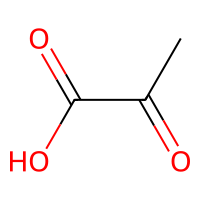
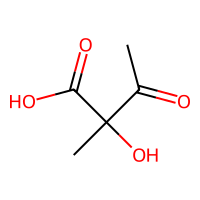
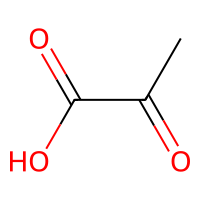
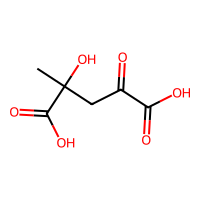
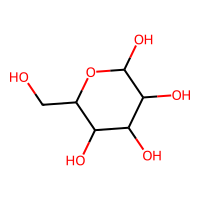
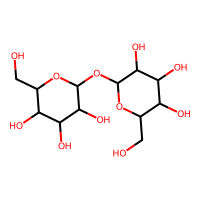
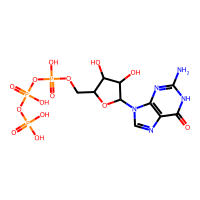
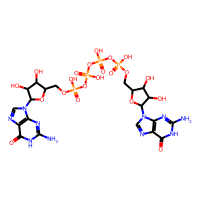
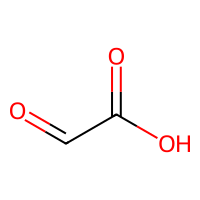
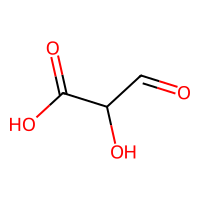
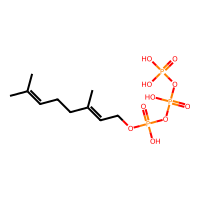
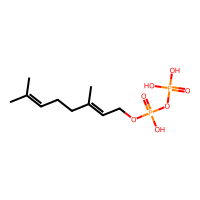
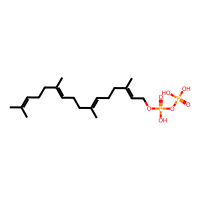
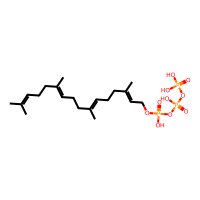
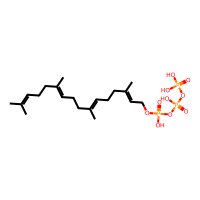
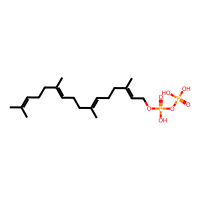
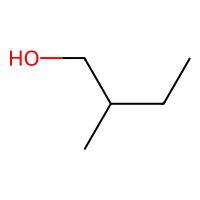
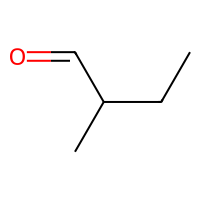
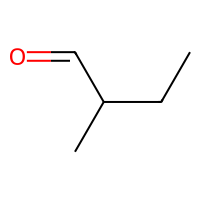
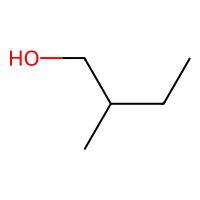

In [94]:
df1_pairs = pd.DataFrame(df1['RPAIR'].tolist(), columns=['Reactant', 'Product'])
df_pairs = pd.concat([df1_pairs, df2, df3], ignore_index=True).drop_duplicates().reset_index(drop=True)
df_pairs['Reactant'] = df_pairs['Reactant'].str.replace(R'@+', '', regex=True)
df_pairs['Product'] = df_pairs['Product'].str.replace(R'@+', '', regex=True)
PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Reactant', molCol='ROMOL_R')
PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Product', molCol='ROMOL_P')
df_pairs = df_pairs.dropna(subset=['ROMOL_R', 'ROMOL_P']).reset_index(drop=True)

df_pairs

In [ ]:
from rdkit.Chem import rdMolDescriptors

def calc_feature_vec(mol, fp='atompair'):
    fp_vec = fpt.calculate_fp(mol, method=fp, as_numpy=True)

    desc_vec = np.array([
        rdMolDescriptors.CalcNumRings(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        rdMolDescriptors.CalcNumAliphaticRings(mol),
        sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() == 6 and a.GetIsAromatic()),
        sum(1 for a in mol.GetAtoms() if a.GetAtomicNum() == 6 and not a.GetIsAromatic())
    ])

    feature_vec = np.concatenate([desc_vec, fp_vec])

    return feature_vec

Pandas Apply:   0%|          | 0/19132 [00:00<?, ?it/s]

Pandas Apply:   0%|          | 0/19132 [00:00<?, ?it/s]

,Reactant,Product,ROMOL_R,ROMOL_P,ATOMS_R,ATOMS_P,ATOM_DIFF,Feature_vec_R,Feature_vec_P
0,CC(=O)C(=O)O,CC(=O)C(C)(O)C(=O)O,,,6,9,3,"[0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,O=CC(=O)O,O=CC(O)C(=O)O,,,5,7,2,"[0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
5,Cc1ncc(C[n+]2csc(CCOP(=O)(O)OP(=O)(O)O)c2C)c(N)n1,Cc1ncc(C[n+]2c(C(C)O)sc(CCOP(=O)(O)OP(=O)(O)O)...,,,26,29,3,"[2, 2, 0, 7, 5, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, ...","[2, 2, 0, 7, 7, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, ..."
9,NCCCCN,NCCCCNCCCCN,,,6,11,5,"[0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 8, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
10,N[CH](CCC(=O)O)C(=O)O,O=C(O)CCC(=O)C(=O)O,,,10,10,0,"[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...,...,...,...,...,...,...
22712,CC(C)=CCC/C(C)=C/COP(=O)(O)OP(=O)(O)OP(=O)(O)O,CC(C)=CCC/C(C)=C/COP(=O)(O)OP(=O)(O)O,,,23,19,4,"[0, 0, 0, 0, 10, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,...","[0, 0, 0, 0, 10, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,..."
22713,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,,,29,33,4,"[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,...","[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,..."
22714,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,CC(C)=CCCC(C)=CCCC(C)=CCCC(C)=CCOP(=O)(O)OP(=O...,,,33,29,4,"[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,...","[0, 0, 0, 0, 20, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0,..."
22715,CCC(C)CO,CCC(C)C=O,,,6,6,0,"[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."

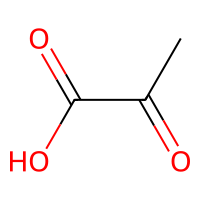
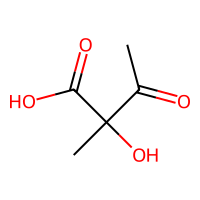
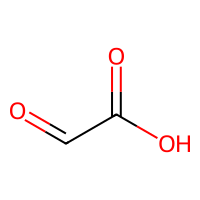
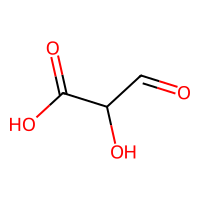
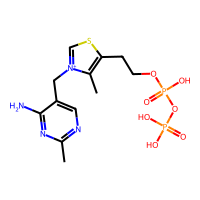
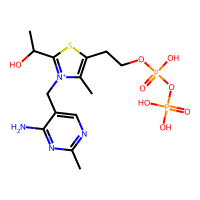
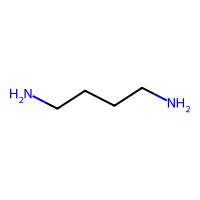
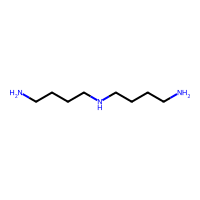
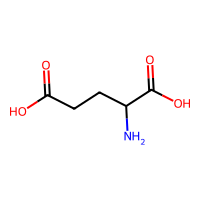
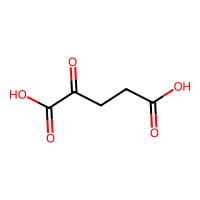
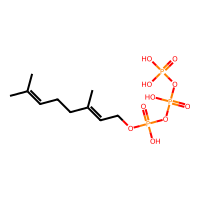
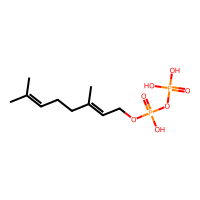
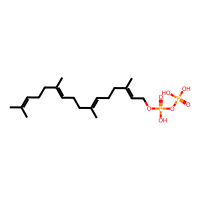
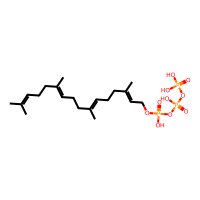
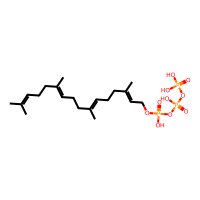
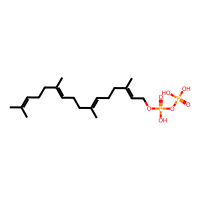
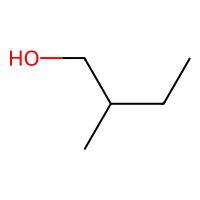
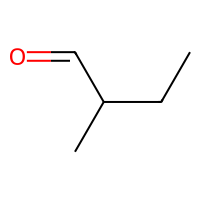
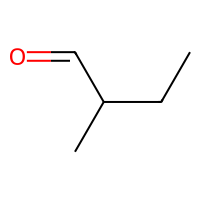
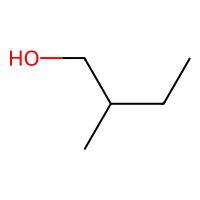

In [95]:
df_pairs['ATOMS_R'] = df_pairs['ROMOL_R'].apply(lambda x: x.GetNumHeavyAtoms() if x else None)
df_pairs['ATOMS_P'] = df_pairs['ROMOL_P'].apply(lambda x: x.GetNumHeavyAtoms() if x else None)
df_pairs['ATOM_DIFF'] = abs(df_pairs['ATOMS_R'] - df_pairs['ATOMS_P'])
df_pairs = df_pairs[df_pairs['ATOM_DIFF'] <= 5]

df_pairs['Feature_vec_R'] = df_pairs['ROMOL_R'].swifter.apply(calc_feature_vec)
df_pairs['Feature_vec_P'] = df_pairs['ROMOL_P'].swifter.apply(calc_feature_vec)

df_pairs

In [98]:
# positives
X_pos = (df_pairs.apply(lambda row: np.abs(row['Feature_vec_R'] - row['Feature_vec_P']),
    axis=1).tolist())
y_pos = [1] * len(X_pos)

# negatives
X_neg, y_neg = [], []
for seed in range(20):
    # shuffle products only
    shuffled_products = df_pairs['ROMOL_P'].sample(
        frac=1, random_state=seed).reset_index(drop=True
    )

    # reset df index too
    shuffled = df_pairs.copy().reset_index(drop=True)
    shuffled['ROMOL_P'] = shuffled_products

    # atom counts and filter
    shuffled['ATOMS_R'] = shuffled['ROMOL_R'].apply(lambda x: x.GetNumHeavyAtoms())
    shuffled['ATOMS_P'] = shuffled['ROMOL_P'].apply(lambda x: x.GetNumHeavyAtoms())
    shuffled['ATOM_DIFF'] = abs(shuffled['ATOMS_R'] - shuffled['ATOMS_P'])
    shuffled = shuffled[shuffled['ATOM_DIFF'] <= 5]

    # recompute feature vectors
    swifter.set_defaults(progress_bar=False)
    shuffled['Feature_vec_R'] = shuffled['ROMOL_R'].swifter.apply(calc_feature_vec)
    shuffled['Feature_vec_P'] = shuffled['ROMOL_P'].swifter.apply(calc_feature_vec)

    # take absolute difference
    neg_features = (
        shuffled.apply(
            lambda row: np.abs(row['Feature_vec_R'] - row['Feature_vec_P']),
            axis=1
        ).tolist()
    )

    X_neg.extend(neg_features)
    y_neg.extend([0] * len(neg_features))

# combine
X = np.array(X_pos + X_neg)
y = np.array(y_pos + y_neg)

In [ ]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report
from xgboost import XGBClassifier
import pandas as pd

kf = KFold(n_splits=5, shuffle=True, random_state=0)

reports = []
for fold, (train_idx, test_idx) in enumerate(kf.split(X), 1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    clf = XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=0,
        use_label_encoder=False,
        eval_metric="logloss")
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    report = classification_report(y_test, y_pred, output_dict=True)
    reports.append(report)

# save model
import joblib
joblib.dump(clf, '../data/xgb_classification.pkl')

# --- summarise across folds ---
df_reports = pd.DataFrame(reports)

summary = {
    "accuracy": df_reports["accuracy"].mean(),
    "precision_macro": df_reports["macro avg"].apply(lambda x: x["precision"]).mean(),
    "recall_macro": df_reports["macro avg"].apply(lambda x: x["recall"]).mean(),
    "f1_macro": df_reports["macro avg"].apply(lambda x: x["f1-score"]).mean(),
    "precision_weighted": df_reports["weighted avg"].apply(lambda x: x["precision"]).mean(),
    "recall_weighted": df_reports["weighted avg"].apply(lambda x: x["recall"]).mean(),
    "f1_weighted": df_reports["weighted avg"].apply(lambda x: x["f1-score"]).mean()}

print("\n=== Mean performance across folds ===")
for k, v in summary.items():
    print(f"{k:20s}: {v:.3f}")


=== Mean performance across folds ===
accuracy            : 0.968
precision_macro     : 0.941
recall_macro        : 0.944
f1_macro            : 0.942
precision_weighted  : 0.969
recall_weighted     : 0.968
f1_weighted         : 0.968


In [ ]:
df_UUL = pd.read_pickle('../data/Database_UUL.pkl')
df_BUL = pd.read_pickle('../data/Database_BUL.pkl')
df_BUL = df_BUL[df_BUL['MW'] > 0]

df_BUL['ATOMS'] = df_BUL['ROMol'].apply(lambda x: x.GetNumHeavyAtoms())
df_BUL['Feature_vec'] = df_BUL['ROMol'].swifter.apply(calc_feature_vec)
df_UUL['ATOMS'] = df_UUL['ROMol'].apply(lambda x: x.GetNumHeavyAtoms())
df_UUL['Feature_vec'] = df_UUL['ROMol'].swifter.apply(calc_feature_vec)

  0%|          | 0/15722 [00:00<?, ?it/s]

,UID,ISOSMILES,ROMol,KID_Similar,ISOSMILES_Similar,ROMol_Similar,Prob_Similar
0,U00001,CC[C@H](C)[C@H](N)CO,,C20310,CC[C@H](C)[C@H](NO)C(=O)O,,0.53
1,U00002,CC[C@@H](O)C[C@H](C)[C@H](O)[C@](C)(O)/C=C/C(=O)O,,C21202,CCCCCCCCC/C=C\C(=O)O,,0.44
2,U00003,C=C(C)[C@@H]1C[C@@]2(C)C(=CC1=O)CC[C@@H](O)[C@...,,C09627,C=C(C)[C@@H]1CC=C2[C@H](O)C[C@@H](O)[C@@H](C)[...,,0.92
3,U00004,C[C@H](C(=O)O)[C@@H](O)/C=C/C=C/C(=O)O,,C12624,O=C(O)/C=C/C(=O)/C=C/C=C(\O)C(=O)O,,0.54
4,U00005,O=C(O)C1=CC(O)C(O)C(O)O1,,C22712,O=C(O)C1=C[C@H](O)[C@@H](O)C(O)O1,,0.98
...,...,...,...,...,...,...,...
15717,U15718,C[C@@H](O)C[C@@H](O)[C@H](Cl)/C=C/C(=O)O,,C04546,C[C@H](CC(=O)O)OC(=O)C[C@@H](C)O,,0.39
15718,U15719,Cc1ccc([C@]2(C)CCCC2(C)C)c(O)c1O,,C17136,Cc1cc(O)c([C@]2(C)CC[C@@H]3C[C@@]32C)cc1Br,,0.80
15719,U15720,Cc1cc([C@@]2(C)CCCC2(C)C)c(O)cc1O,,C20180,CC1=CC=C([C@]2(C)CCCC2(C)C)CC1,,0.84
15720,U15721,C[C@@H](O)[C@H]1[C@@](C)(O)CC(=O)[C@]23O[C@]12...,,C10439,C[C@@H]1O[C@@H](OC[C@H]2O[C@@H](OCCc3ccc(O)cc3...,,0.21

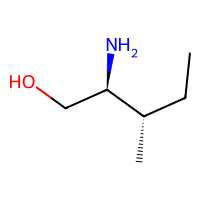
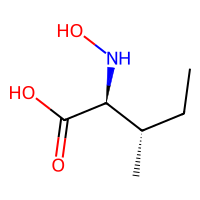
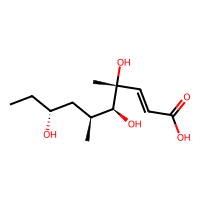
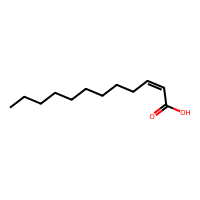
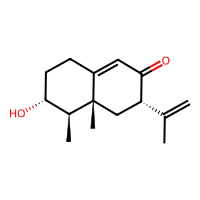
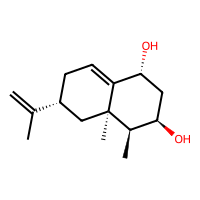
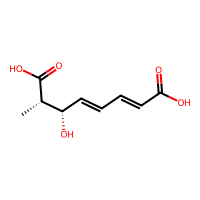
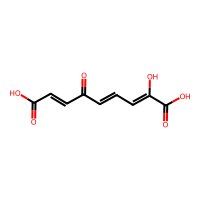
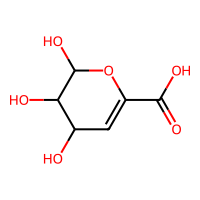
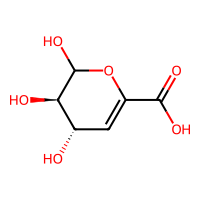
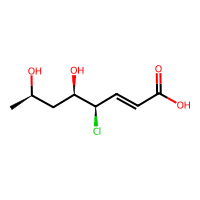
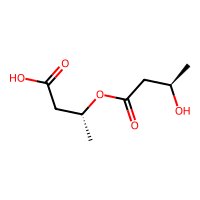
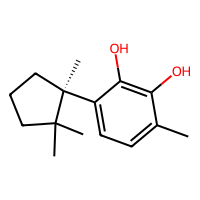
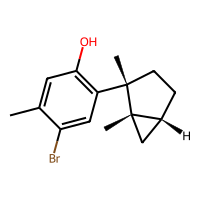
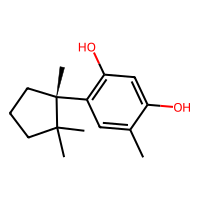
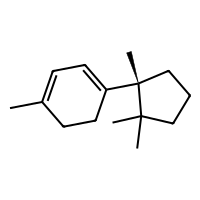
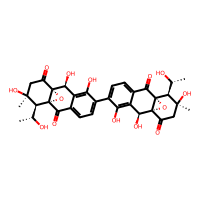
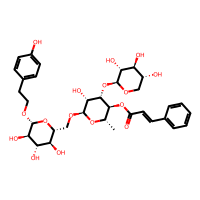
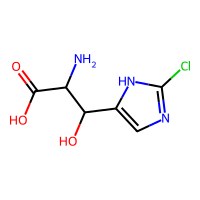
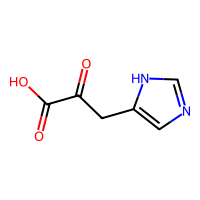

In [ ]:
BUL_fvs = np.stack(df_BUL['Feature_vec'].values)     # stacked feature vectors
BUL_atoms = df_BUL['ATOMS'].values                   # atom counts

results = []

for uul in tqdm(df_UUL.itertuples(index=False), total=len(df_UUL)):
    fv_u = uul.Feature_vec
    num_atoms_u = uul.ATOMS

    # filter BUL candidates by atom count difference
    mask = abs(BUL_atoms - num_atoms_u) <= 5
    fvs_filtered = BUL_fvs[mask]
    bul_subset = df_BUL.loc[mask]

    # compute all probabilities at once
    diffs = np.abs(fvs_filtered - fv_u)
    probs = clf.predict_proba(diffs)[:, 1]

    # most similar candidate
    if len(bul_subset) > 0:
        Similar_idx = np.argmax(probs)
        Similar_row = bul_subset.iloc[Similar_idx]
        results.append([Similar_row.ID, Similar_row.ISOSMILES, probs[Similar_idx]])
    else:
        results.append(['', '', 0])

df_UUL[['KID_Similar', 'ISOSMILES_Similar', 'Prob_Similar']] = results
df_UUL['Prob_Similar'] = pd.to_numeric(df_UUL['Prob_Similar'], errors='coerce')
df_UUL['Prob_Similar'] = df_UUL['Prob_Similar'].round(2)
PandasTools.AddMoleculeColumnToFrame(df_UUL, smilesCol='ISOSMILES_Similar', molCol='ROMol_Similar')
df_UUL['InChI'] = df_UUL['ROMol'].apply(lambda x: Chem.MolToInchi(x))

df_UUL = df_UUL[['UID', 'ISOSMILES', 'InChI', 'ROMol', 'KID_Similar', 'ISOSMILES_Similar', 'ROMol_Similar', 'Prob_Similar']]
df_UUL.drop(columns=['ROMol', 'ROMol_Similar']).to_csv('data/Database_UUL.csv', index=False)
df_UUL.to_pickle('data/Database_UUL.pkl')

df_UUL

In [1]:
df_UUL

NameError: name 'df_UUL' is not defined